# Homework 04: Building CNNs for Image Classification

### Due: September 27th at 11:59pm (with 2-hour + 1 minute grace period) and worth 85 points

In this assignment, you will take your first steps into designing and training convolutional neural networks (CNNs) for image classification. Starting from a simple baseline, you will experiment with modifications that reflect the kinds of design choices practitioners face every day. Along the way, you’ll see how architecture, hyperparameters, normalization, pooling strategies, and learning rate schedules can each shape a model’s performance.

The problems are organized to build on each other:

1. **Hyperparameters:** Begin with a baseline CNN and try variations in learning rate, layer width, depth, and dropout.
2. **Batch Normalization:** Add normalization after convolutional layers to stabilize training and speed convergence.
3. **Global Average Pooling:** Replace the flatten-and-dense head with a modern pooling layer, reducing parameters and improving generalization.
4. **ReduceLROnPlateau:** Explore a widely used learning rate scheduler that adapts when validation progress slows.
5. **Very Deep CNN:** Finally, run a VGG-16–style model to observe how deeper networks behave compared to smaller ones.

By the end of this homework, you will have hands-on experience with both classical and modern CNN design strategies, a sense of how different components affect learning, and a toolkit of techniques that will serve you in future image processing projects.

There are 10 graded questions, worth 8 points each, with 5 points free if you complete all of the graded questions in the homework.


## 1. Setup and Data Loading


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import os,time,random,kagglehub

import tensorflow as tf
from tensorflow.keras import layers, Input, models, callbacks, regularizers,initializers
from tensorflow.keras.callbacks import Callback,EarlyStopping,ReduceLROnPlateau
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical, load_img, img_to_array
from tensorflow.keras.optimizers import Adam,AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay, ExponentialDecay
from tensorflow.keras.preprocessing.image import ImageDataGenerator,load_img, img_to_array
from tensorflow.keras.layers import Dense,Input,Dropout,Flatten,MaxPooling2D,Conv2D,SeparableConv2D,GlobalAveragePooling2D,GlobalMaxPooling2D,BatchNormalization

from sklearn.model_selection import train_test_split

# utility code

# -------------------------
# Reproducibility settings
# -------------------------

random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
tf.keras.utils.set_random_seed(random_seed)

def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Suppresses INFO and WARNING messages

### Utility function to plot learning curves and keep track of all results

- Call `print_results()` to see listing of all results logged so far

In [3]:

def plot_learning_curves(hist, title, verbose=True):

    val_losses = hist.history['val_loss']
    min_val_loss = min(val_losses)
    min_val_epoch = val_losses.index(min_val_loss)
    val_acc_at_min_loss = hist.history['val_accuracy'][min_val_epoch]

    epochs = range(1, len(val_losses) + 1)  # epoch numbers starting at 1

    fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

    # --- Loss Plot ---
    axs[0].plot(epochs, hist.history['loss'], label='train loss')
    axs[0].plot(epochs, hist.history['val_loss'], label='val loss')
    axs[0].scatter(min_val_epoch + 1, min_val_loss, color='red', marker='x', s=50, label='min val loss')
    axs[0].set_title(f'{title} - Categorical Cross-Entropy Loss')
    axs[0].set_ylabel('Loss')
    axs[0].legend()
    axs[0].grid(True)

    # --- Accuracy Plot ---
    axs[1].plot(epochs, hist.history['accuracy'], label='train acc')
    axs[1].plot(epochs, hist.history['val_accuracy'], label='val acc')
    axs[1].scatter(min_val_epoch + 1, val_acc_at_min_loss, color='red', marker='x', s=50, label='acc @ min val loss')
    axs[1].set_title(f'{title} - Accuracy')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('Accuracy')
    axs[1].legend()
    axs[1].grid(True)
    axs[1].set_ylim(0, 1.05)

    plt.tight_layout()
    plt.show()

    if verbose:
        print(f"Final Training Loss:            {hist.history['loss'][-1]:.4f}")
        print(f"Final Training Accuracy:        {hist.history['accuracy'][-1]:.4f}")
        print(f"Final Validation Loss:          {hist.history['val_loss'][-1]:.4f}")
        print(f"Final Validation Accuracy:      {hist.history['val_accuracy'][-1]:.4f}")
        print(f"Minimum Validation Loss:        {min_val_loss:.4f} (Epoch {min_val_epoch + 1})")
        print(f"Validation Accuracy @ Min Loss: {val_acc_at_min_loss:.4f}")

    results[title] = (val_acc_at_min_loss,min_val_epoch + 1)

results = {}

def print_results():
    for title, (acc, ep) in sorted(results.items(),
                                   key=lambda kv: kv[1][0],   # kv[1] is (acc, epoch); [0] is acc
                                   reverse=True
                                  ):
        print(f"{title:<40}\t{acc:.4f}\t{ep}")

###  Wrapper for training and testing

#### Assumptions:   
- Early stopping is default, add other callbacks as needed
- Testing and training sets already defined, accessed here as global variables

###  Wrapper for training and testing

#### Assumptions:   
- Early stopping is default, add other callbacks as needed
- Training and testing sets already defined, accessed here as global variables

In [4]:
# Uses globals: train_ds, val_ds, test_ds

def train_and_test(model,
                   epochs        = 500,
                   lr_schedule   = 1e-3,
                   optimizer     = "Adam",
                   title         = "Learning Curves",
                   use_early_stopping = True,
                   patience      = 10,
                   min_delta     = 0.0001,
                   callbacks     = [],
                   verbose       = 0,
                   return_history = False
                  ):

    print(f"\n{title}\n")

    # Choose optimizer
    if optimizer == "Adam":
        opt = Adam(learning_rate=lr_schedule)
    else:
        opt = optimizer

    # Compile
    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=min_delta,
        restore_best_weights=True,
        verbose=verbose
    )

    cbs = ([early_stop] if use_early_stopping else []) + callbacks

    start = time.time()

    # Fit on tf.data datasets (already batched)
    history = model.fit(
        train_ds,
        epochs=epochs,
        validation_data=val_ds,
        callbacks=cbs,
        verbose=verbose
    )

    # Determine best validation accuracy
    if use_early_stopping and hasattr(early_stop, "best_epoch") and early_stop.best_epoch is not None:
        best_epoch = early_stop.best_epoch
        best_acc   = history.history['val_accuracy'][best_epoch]
    else:
        best_epoch = int(np.argmax(history.history['val_accuracy']))
        best_acc   = history.history['val_accuracy'][best_epoch]

    plot_learning_curves(history, title=title)

    # Evaluate on tf.data test set
    test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

    print(f"\nTest Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"\nValidation-Test Gap (accuracy): {abs(best_acc - test_accuracy):.6f}")

    end = time.time()
    print(f"\nExecution Time: " + format_hms(end-start))

    if return_history:
        return history


### Load the Intel Image Classification Dataset  



In [5]:
path      = kagglehub.dataset_download("puneet6060/intel-image-classification")
train_dir = os.path.join(path, "seg_train/seg_train")
test_dir  = os.path.join(path, "seg_test/seg_test")

Using Colab cache for faster access to the 'intel-image-classification' dataset.


In [6]:
import os
import numpy as np
import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE

def list_files_and_labels(directory, class_names=None, exts=(".jpg", ".jpeg", ".png")):
    """
    Returns:
      filepaths: np.array[str]
      labels:    np.array[int32]
      class_names_used: list[str] in deterministic order
    """
    if class_names is None:
        class_names = sorted(
            d for d in os.listdir(directory)
            if os.path.isdir(os.path.join(directory, d))
        )
    else:
        # keep only classes that exist in this directory, preserve given order
        class_names = [c for c in class_names if os.path.isdir(os.path.join(directory, c))]

    class_to_idx = {name: idx for idx, name in enumerate(class_names)}

    filepaths = []
    labels = []

    for cname in class_names:
        folder = os.path.join(directory, cname)
        for fname in sorted(os.listdir(folder)):  # deterministic within class
            if fname.lower().endswith(exts):
                filepaths.append(os.path.join(folder, fname))
                labels.append(class_to_idx[cname])

    return np.array(filepaths), np.array(labels, dtype=np.int32), class_names


def stratified_split_indices(y, val_frac=0.2, seed=42):
    """
    Deterministic stratified split over indices.
    Returns: train_idx, val_idx (np arrays)
    """
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    n = len(y)

    train_idx_list = []
    val_idx_list = []

    classes = np.unique(y)
    for c in classes:
        idx = np.flatnonzero(y == c)
        rng.shuffle(idx)
        n_val = int(np.floor(len(idx) * val_frac))
        val_idx_list.append(idx[:n_val])
        train_idx_list.append(idx[n_val:])

    train_idx = np.concatenate(train_idx_list)
    val_idx = np.concatenate(val_idx_list)

    # Optional: shuffle each split deterministically so batches mix classes
    rng.shuffle(train_idx)
    rng.shuffle(val_idx)

    return train_idx, val_idx


def make_image_dataset(filepaths, labels, img_size=(150, 150), batch_size=32,
                       shuffle=False, seed=42, cache_to_disk=None):
    """
    Builds a tf.data.Dataset that loads images lazily from disk.
    - filepaths: np array of strings
    - labels:    np array of int32
    """
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))

    if shuffle:
        # shuffle file *references* (cheap), not image tensors
        ds = ds.shuffle(buffer_size=len(filepaths), seed=seed, reshuffle_each_iteration=True)

    def _load_and_preprocess(path, label):
        # read bytes -> decode -> resize -> float32 in [0,1]
        img_bytes = tf.io.read_file(path)
        img = tf.image.decode_image(img_bytes, channels=3, expand_animations=False)
        img = tf.image.resize(img, img_size, method="bilinear")
        img = tf.cast(img, tf.float32) / 255.0
        return img, label

    ds = ds.map(_load_and_preprocess, num_parallel_calls=AUTOTUNE)

    if cache_to_disk is not None:
        # Disk caching avoids RAM blowups; /tmp is fine in Colab
        ds = ds.cache(cache_to_disk)

    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds


# -------------------------
# Example usage for Intel dataset
# -------------------------

IMG_SIZE    = (150, 150)
INPUT_SHAPE = IMG_SIZE + (3,)
BATCH_SIZE  = 32
VAL_FRAC    = 0.2
SEED        = random_seed  # use your existing seed

# 1) List train files/labels deterministically
train_files, train_labels, class_names = list_files_and_labels(train_dir)

num_classes = len(class_names)

# 2) Stratified deterministic split of *indices* (no images loaded)
train_idx, val_idx = stratified_split_indices(train_labels, val_frac=VAL_FRAC, seed=SEED)

# 3) Slice file lists
files_train = train_files[train_idx]
y_train     = train_labels[train_idx]
files_val   = train_files[val_idx]
y_val       = train_labels[val_idx]

# 4) Build datasets (lazy image loading)
train_ds = make_image_dataset(files_train, y_train, img_size=IMG_SIZE,
                              batch_size=BATCH_SIZE, shuffle=True, seed=SEED,
                              cache_to_disk=None)

val_ds   = make_image_dataset(files_val, y_val, img_size=IMG_SIZE,
                              batch_size=BATCH_SIZE, shuffle=False,
                              cache_to_disk=None)

# 5) Test set: keep same class mapping as train
test_files, test_labels, _ = list_files_and_labels(test_dir, class_names=class_names)
test_ds = make_image_dataset(test_files, test_labels, img_size=IMG_SIZE,
                             batch_size=BATCH_SIZE, shuffle=False,
                             cache_to_disk=None)




### Examine The Dataset

In [7]:

def show_counts_from_labels(name, labels, class_names):
    c = Counter(labels.tolist())
    counts = {class_names[k]: c.get(k, 0) for k in range(len(class_names))}
    print(f"{name} per-class counts:", counts)

print("class_names:", class_names)
print("train examples:", len(files_train), "val examples:", len(files_val), "test examples:", len(test_files))

show_counts_from_labels("train", y_train, class_names)
show_counts_from_labels("val",   y_val,   class_names)
show_counts_from_labels("test",  test_labels, class_names)


class_names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
train examples: 11230 val examples: 2804 test examples: 3000
train per-class counts: {'buildings': 1753, 'forest': 1817, 'glacier': 1924, 'mountain': 2010, 'sea': 1820, 'street': 1906}
val per-class counts: {'buildings': 438, 'forest': 454, 'glacier': 480, 'mountain': 502, 'sea': 454, 'street': 476}
test per-class counts: {'buildings': 437, 'forest': 474, 'glacier': 553, 'mountain': 525, 'sea': 510, 'street': 501}


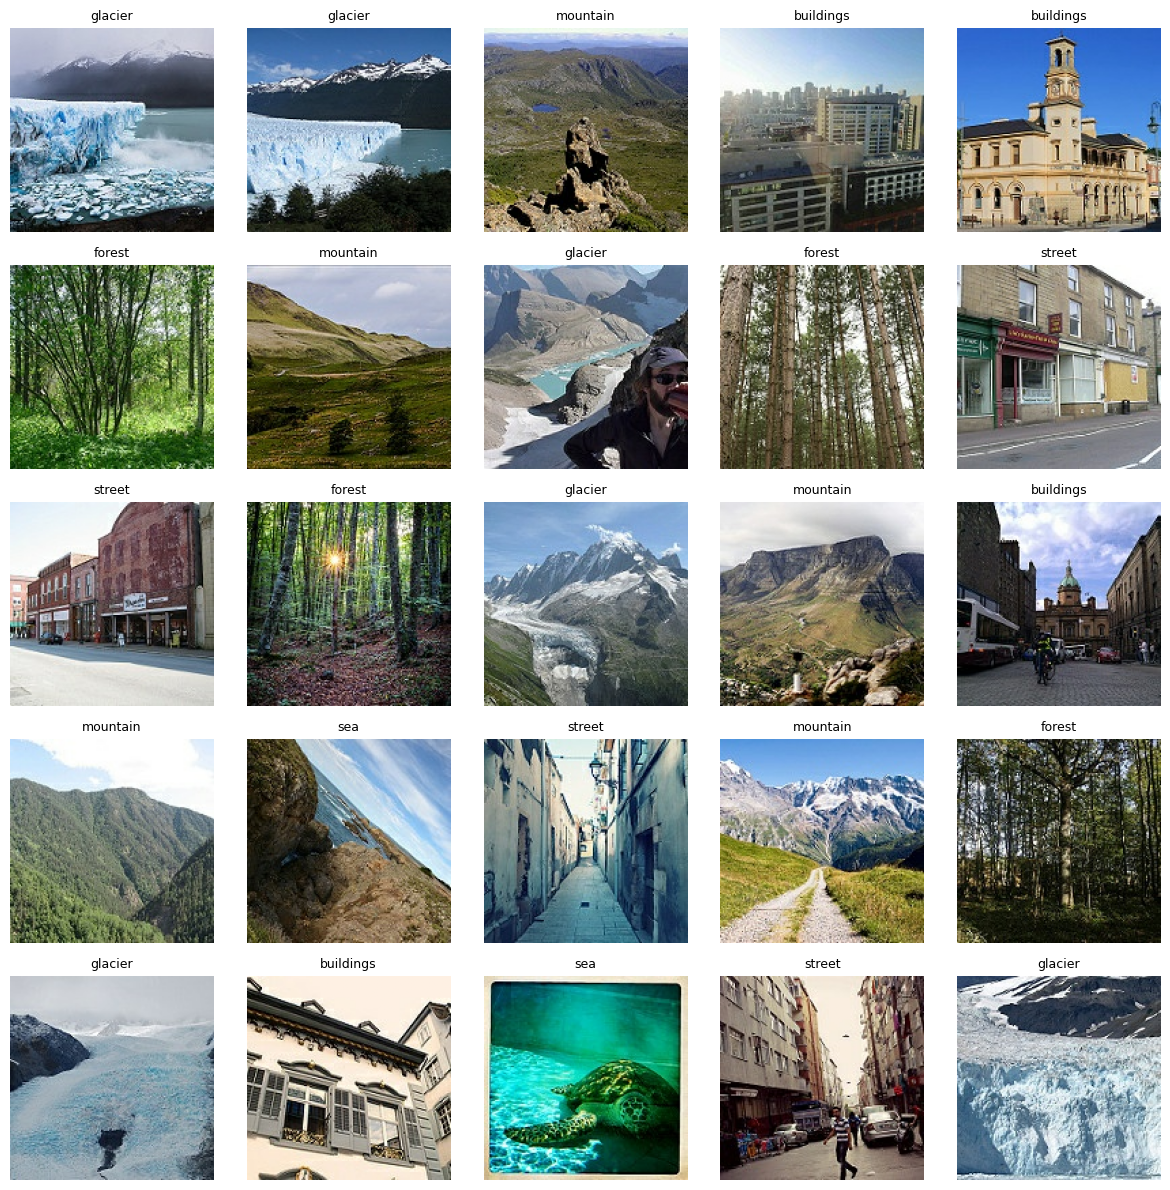

In [8]:
# Show 25 sample images

plt.figure(figsize=(12, 12))

# Take one batch from the dataset
images, labels = next(iter(train_ds))

for i in range(25):
    ax = plt.subplot(5, 5, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(class_names[int(labels[i])], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()


### Prelude: Baseline CNN (reference model)

This is our **reference** network: two Conv→Pool blocks with channels **32 → 64**, followed by a **single hidden head** `Dense(64)`. We use **He** initialization for ReLU activations and include an **optional `Dropout(0.5)`** to illustrate regularization—comment it out to gauge its impact (ha, not really optional!).

Use this model as a stable yardstick while you run **ablations**: change **one knob at a time** (e.g., widen/deepen the conv blocks, adjust dropout rate, add batch norm, tweak the LR schedule) and compare results back to this baseline. Focus on **training vs. validation curves**, the **generalization gap**, and how dropout affects **val loss/accuracy** and how long it takes for Early Stopping to kick in.


> **Note:** On rare runs, training may become numerically unstable and produce `NaN` loss values. If this occurs, rerun the model. If the problem persists, restart the runtime and run the notebook again from the beginning.


Baseline Model



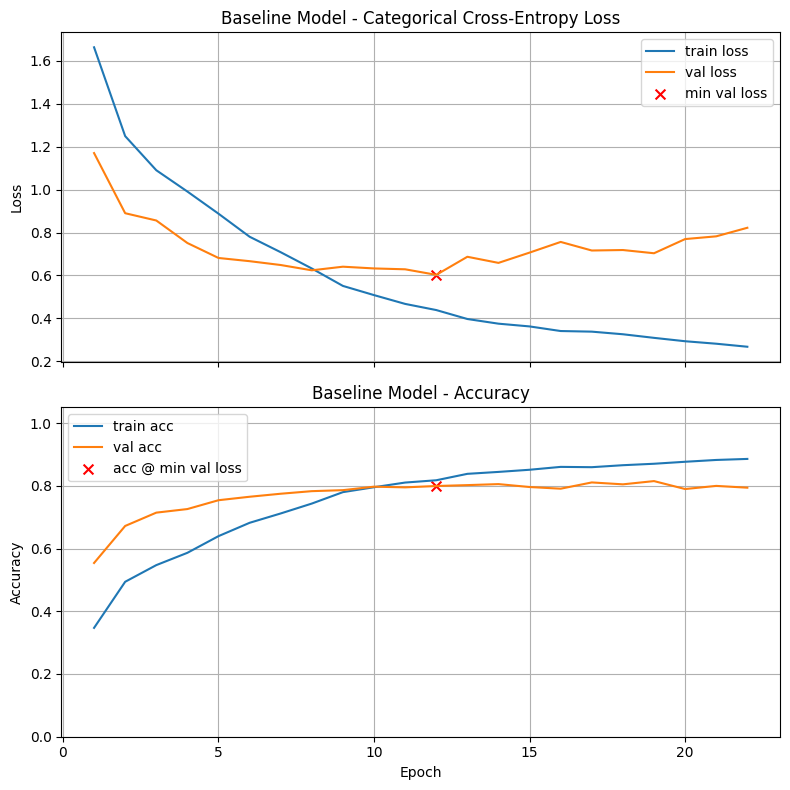

Final Training Loss:            0.2685
Final Training Accuracy:        0.8856
Final Validation Loss:          0.8220
Final Validation Accuracy:      0.7939
Minimum Validation Loss:        0.6030 (Epoch 12)
Validation Accuracy @ Min Loss: 0.7992

Test Loss: 0.6442
Test Accuracy: 0.8063

Validation-Test Gap (accuracy): 0.007118

Execution Time: 00:04:34


In [9]:
he = initializers.HeNormal()                                # best initializer for relu

model_baseline= models.Sequential([
    Input(shape=INPUT_SHAPE),

    Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
    MaxPooling2D(2),

    Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
    MaxPooling2D(2),

    Flatten(),
    Dense(64, activation="relu",kernel_initializer=he),
    Dropout(0.5),
    Dense(num_classes, activation="softmax")
])

train_and_test(model_baseline,title=f"Baseline Model")


## Problem One: Exploring Basic Hyperparameters

**Task:**
Copy the baseline CNN model into the next cell and experiment with basic hyperparameter changes. Your goal is to see whether small tweaks can improve validation accuracy (and hopefully speed up convergence or produce smoother training curves). You must **pick 3 of the following tweaks** and investigate their effect:

**Tweaks to Try:**

1. Adjust the learning rate (default for Adam is `1e-3`).
2. Change the width of the `Conv2D` layers (e.g., 64 → 128).
3. Add an extra `Conv2D` layer (e.g., stack 32 → 64 → 128).
4. Change the width of the `Dense(64 ...)` layer.
5. Add L2 regularization to the `Dense(64 ...)` layer (see the head of the network in Problem 5 for inspiration).  
6. Modify the dropout rate.
   
Observe the effect of each of your 3 choices in isolation and answer the graded questions.

**Optional:**
Combine two or more changes to see if they work together to improve results (example: try L2 regularization and reduced dropout in the head, as in Problem 5).


**Pro Tip:** Give each experiment a descriptive title, such as "Problem 1 -- Tweak 1 -- lr: 0.0005" to keep track of your experiments (see last cell in the notebook).


lr-adjust



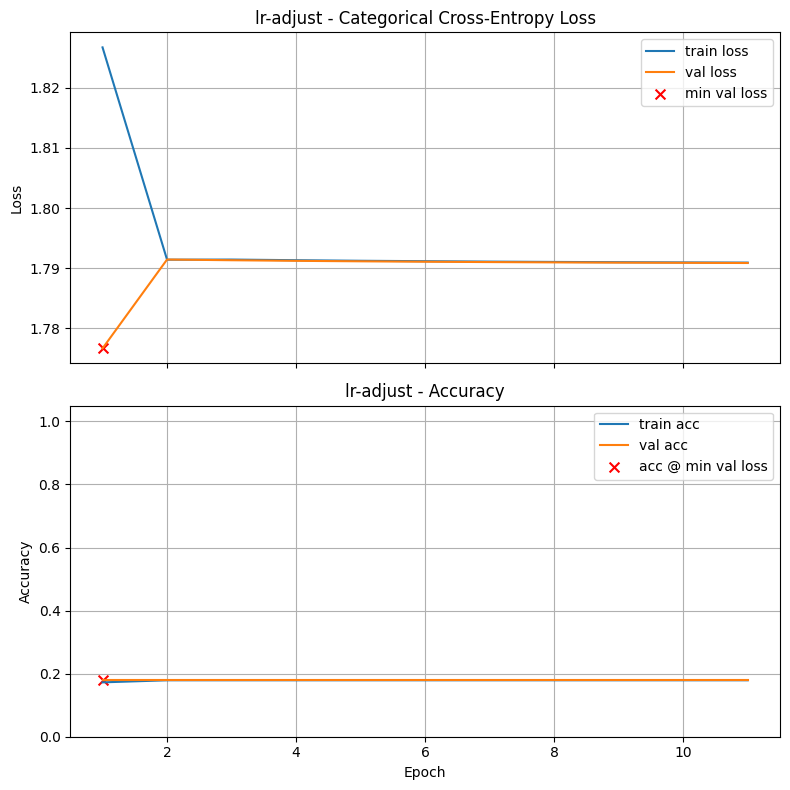

Final Training Loss:            1.7909
Final Training Accuracy:        0.1790
Final Validation Loss:          1.7909
Final Validation Accuracy:      0.1794
Minimum Validation Loss:        1.7767 (Epoch 1)
Validation Accuracy @ Min Loss: 0.1794

Test Loss: 1.7787
Test Accuracy: 0.1750

Validation-Test Gap (accuracy): 0.004387

Execution Time: 00:01:51

layer-width



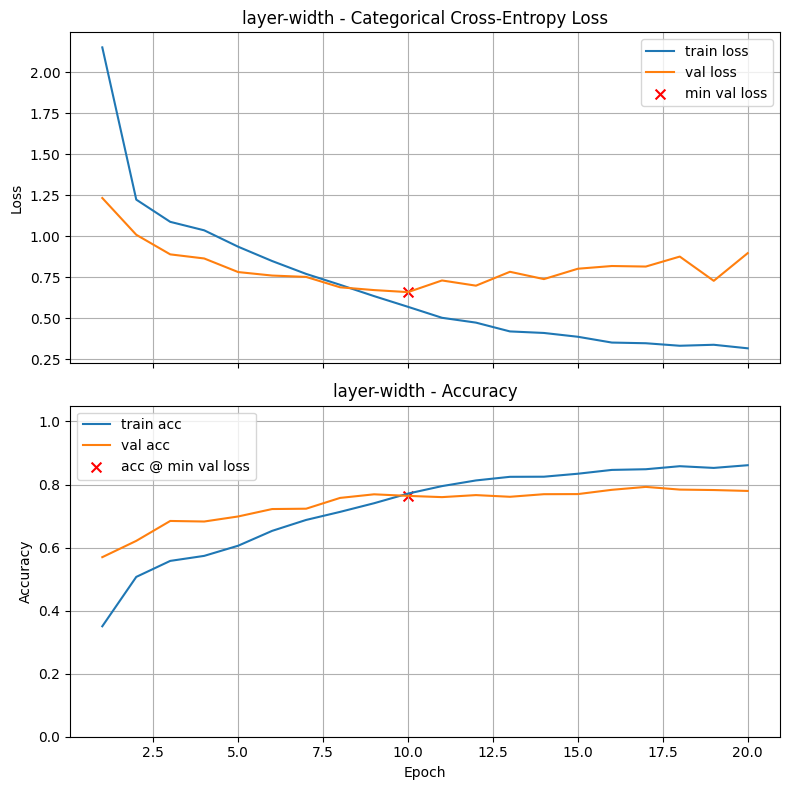

Final Training Loss:            0.3165
Final Training Accuracy:        0.8612
Final Validation Loss:          0.8972
Final Validation Accuracy:      0.7796
Minimum Validation Loss:        0.6594 (Epoch 10)
Validation Accuracy @ Min Loss: 0.7639

Test Loss: 0.6733
Test Accuracy: 0.7710

Validation-Test Gap (accuracy): 0.007091

Execution Time: 00:05:35

2d-layer



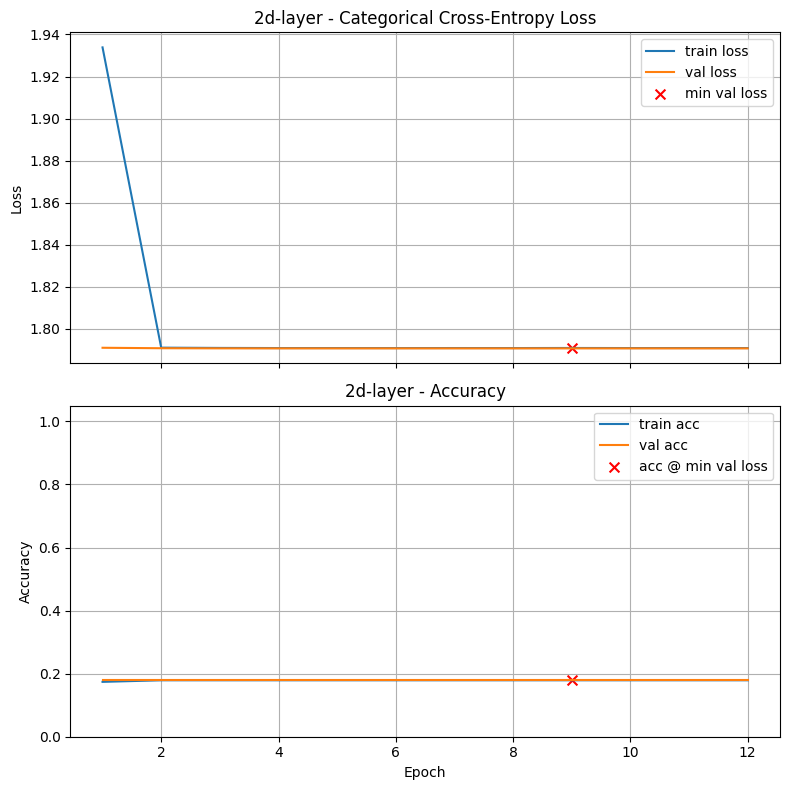

Final Training Loss:            1.7909
Final Training Accuracy:        0.1790
Final Validation Loss:          1.7908
Final Validation Accuracy:      0.1790
Minimum Validation Loss:        1.7908 (Epoch 9)
Validation Accuracy @ Min Loss: 0.1790

Test Loss: 1.7904
Test Accuracy: 0.1750

Validation-Test Gap (accuracy): 0.004030

Execution Time: 00:02:37

layer-width



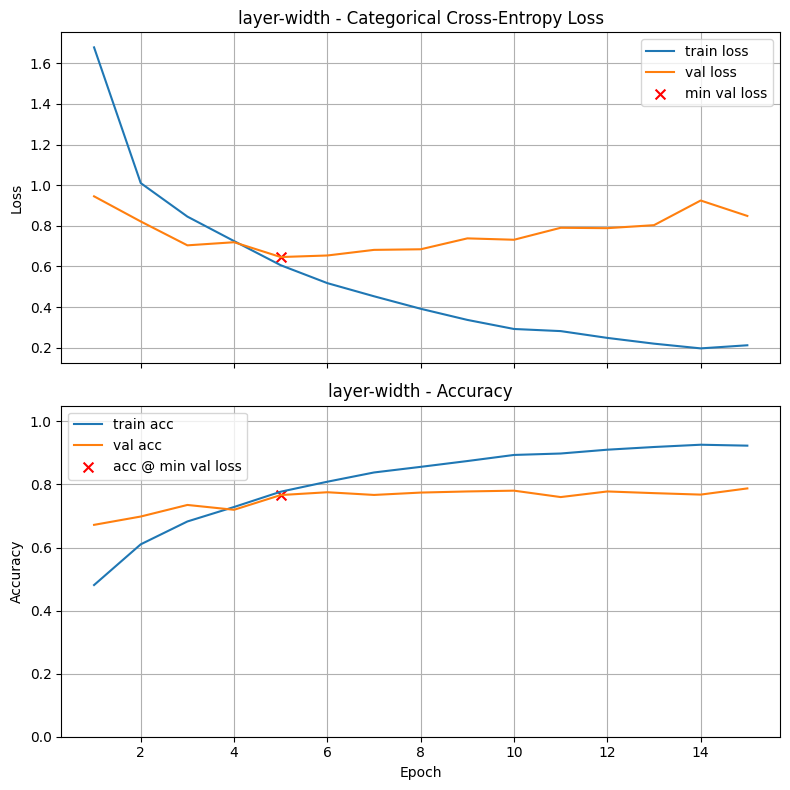

Final Training Loss:            0.2120
Final Training Accuracy:        0.9231
Final Validation Loss:          0.8487
Final Validation Accuracy:      0.7874
Minimum Validation Loss:        0.6464 (Epoch 5)
Validation Accuracy @ Min Loss: 0.7664

Test Loss: 0.6872
Test Accuracy: 0.7780

Validation-Test Gap (accuracy): 0.011595

Execution Time: 00:02:34

drop_out



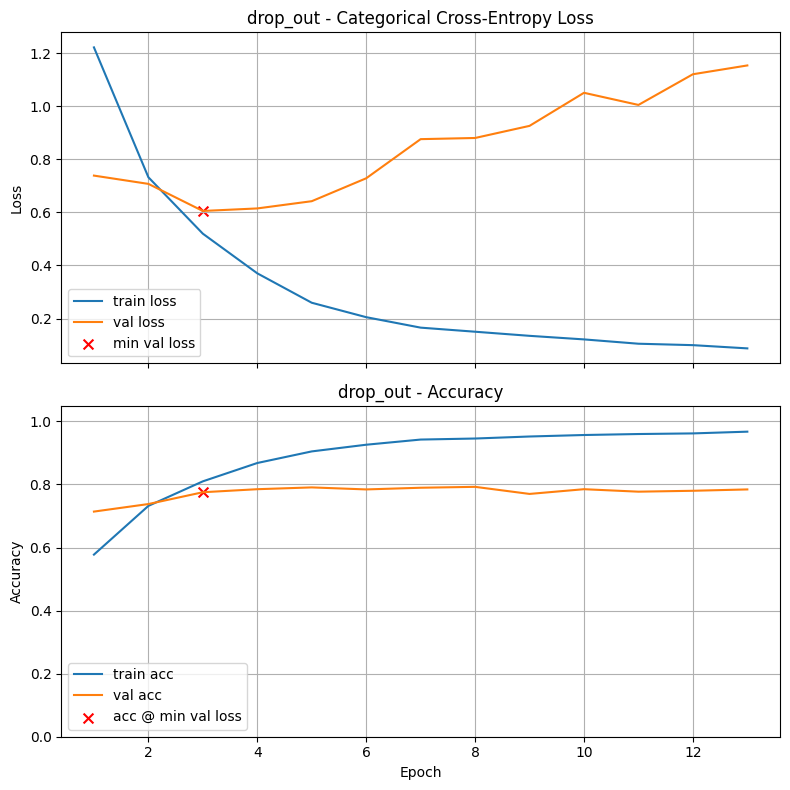

Final Training Loss:            0.0880
Final Training Accuracy:        0.9674
Final Validation Loss:          1.1532
Final Validation Accuracy:      0.7842
Minimum Validation Loss:        0.6053 (Epoch 3)
Validation Accuracy @ Min Loss: 0.7753

Test Loss: 0.6314
Test Accuracy: 0.7817

Validation-Test Gap (accuracy): 0.006346

Execution Time: 00:02:12


In [17]:
# Tweak 3

model_list = []


# model 1 change lr #1
he = initializers.HeNormal()                                # best initializer for relu

model_learnrate = models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Flatten(),
  Dense(64, activation="relu",kernel_initializer=he),
  Dropout(0.5),
  Dense(num_classes, activation="softmax")
],name="learn_rate")
hist1 = train_and_test(model_learnrate,lr_schedule=1e-4,title="lr-adjust",return_history=True)
model_list.append(hist1)

# model 2 change width #2
he = initializers.HeNormal()                                # best initializer for relu

model_layer_width= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Conv2D(128, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Flatten(),
  Dense(64, activation="relu",kernel_initializer=he),
  Dropout(0.5),
  Dense(num_classes, activation="softmax")
],name="layer_width")
hist2 = train_and_test(model_layer_width,title="layer-width",return_history=True)
model_list.append(hist2)

# model 3 add 2d layer #3
he = initializers.HeNormal()                                # best initializer for relu

model_conv2d= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Conv2D(128, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Flatten(),
  Dense(32, activation="relu",kernel_initializer=he),
  Dropout(0.5),
  Dense(num_classes, activation="softmax")
],name="2d-layer")
hist3 = train_and_test(model_conv2d,title="2d-layer",return_history=True)
model_list.append(hist3)

# model 4 dense #4
he = initializers.HeNormal()                                # best initializer for relu

model_layer_width= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Flatten(),
  Dense(128, activation="relu",kernel_initializer=he),
  Dropout(0.5),
  Dense(num_classes, activation="softmax")
],name="layer_width")
hist4 = train_and_test(model_layer_width,title="layer-width",return_history=True)
model_list.append(hist4)


# model 6 change dropout #6
he = initializers.HeNormal()                                # best initializer for relu

model_dropout= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  MaxPooling2D(2),

  Flatten(),
  Dense(64, activation="relu",kernel_initializer=he),
  Dropout(0.25),
  Dense(num_classes, activation="softmax")
],name="dropout")
hist6 = train_and_test(model_dropout,title="drop_out",return_history=True)
model_list.append(hist6)



### Graded Questions

In [11]:
# Set a1a to the number of the individual "tweak" which provided the best validation accuracy at the epoch of minimum validation loss

a1a = -1             # Replace with integer 1 - 6; replace with -1 if you found no tweak which improved the results

In [12]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a1a = {a1a}')


a1a = -1


In [22]:
# Set a1b to the validation accuracy found by the choice specified in Question a1a.

a1b = max(model_list[a1a].history['val_accuracy'])            # Replace 0.0 with your answer

In [23]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a1b = {a1b:.4f}')

a1b = 0.7924


## Problem Two: Adding Batch Normalization

**Task:**
Take your best model from Problem One and add a `BatchNormalization()` layer immediately after each `Conv2D` layer. Batch normalization helps stabilize training and can improve convergence.

**Next Steps:**

* Train the model with batch normalization included after each `Conv2D` layer.
* Try at least one of tweaks from Problem 1 to see if you can improve your results in this new design.
* Compare the results to your earlier experiments and answer the graded questions.

**Optional:**
Try more than one hyperparameter change alongside batch normalization and see how they interact.




lr-adjust-batch



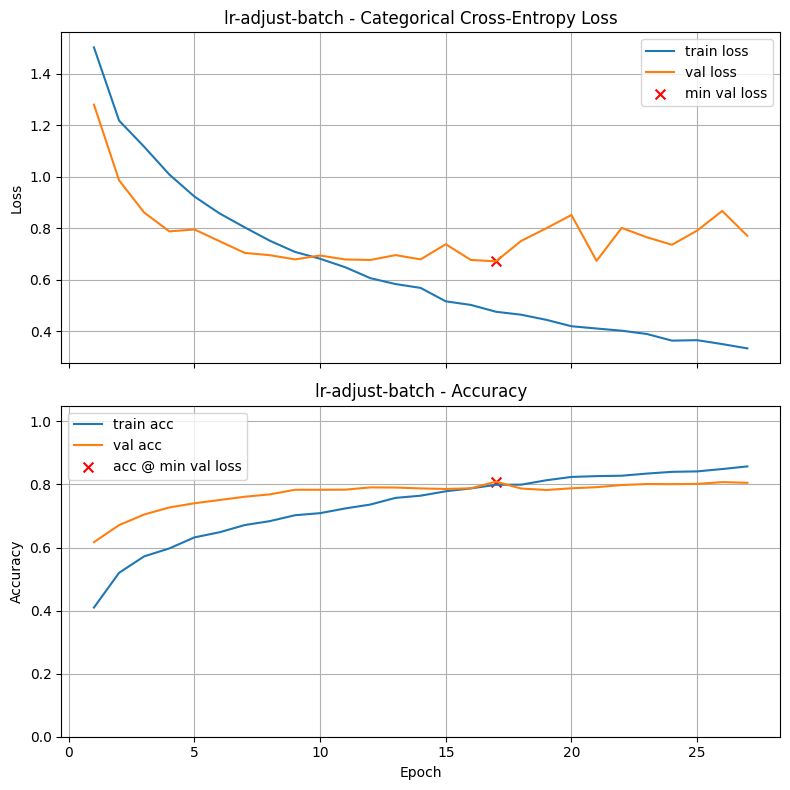

Final Training Loss:            0.3329
Final Training Accuracy:        0.8573
Final Validation Loss:          0.7703
Final Validation Accuracy:      0.8053
Minimum Validation Loss:        0.6713 (Epoch 17)
Validation Accuracy @ Min Loss: 0.8088

Test Loss: 0.7445
Test Accuracy: 0.7913

Validation-Test Gap (accuracy): 0.017511

Execution Time: 00:06:11

layer-width_bacth



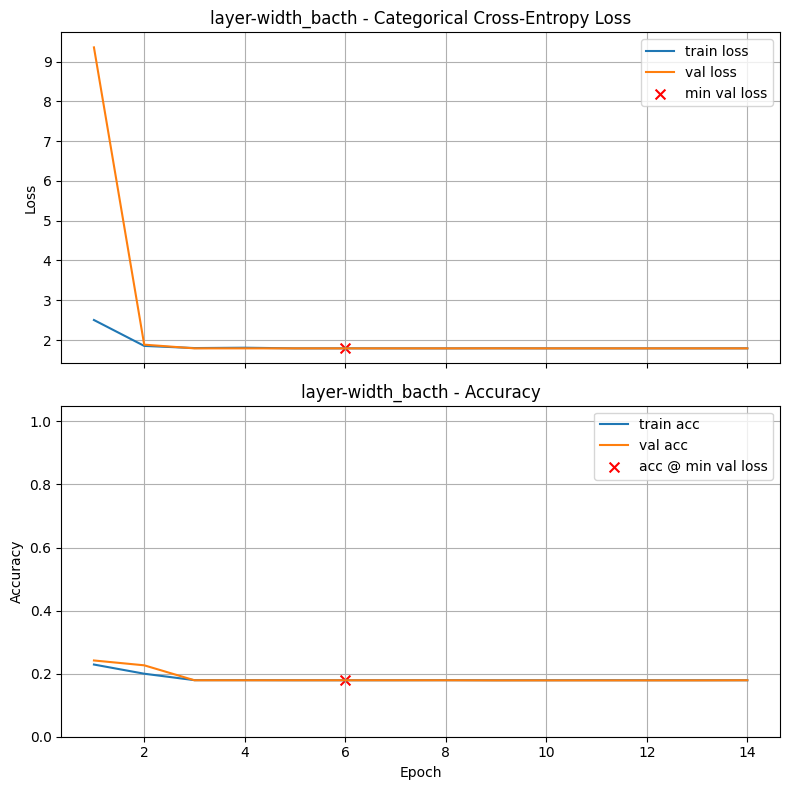

Final Training Loss:            1.7918
Final Training Accuracy:        0.1791
Final Validation Loss:          1.7908
Final Validation Accuracy:      0.1790
Minimum Validation Loss:        1.7908 (Epoch 6)
Validation Accuracy @ Min Loss: 0.1790

Test Loss: 1.7901
Test Accuracy: 0.1750

Validation-Test Gap (accuracy): 0.004030

Execution Time: 00:04:41

2d-layer_batch



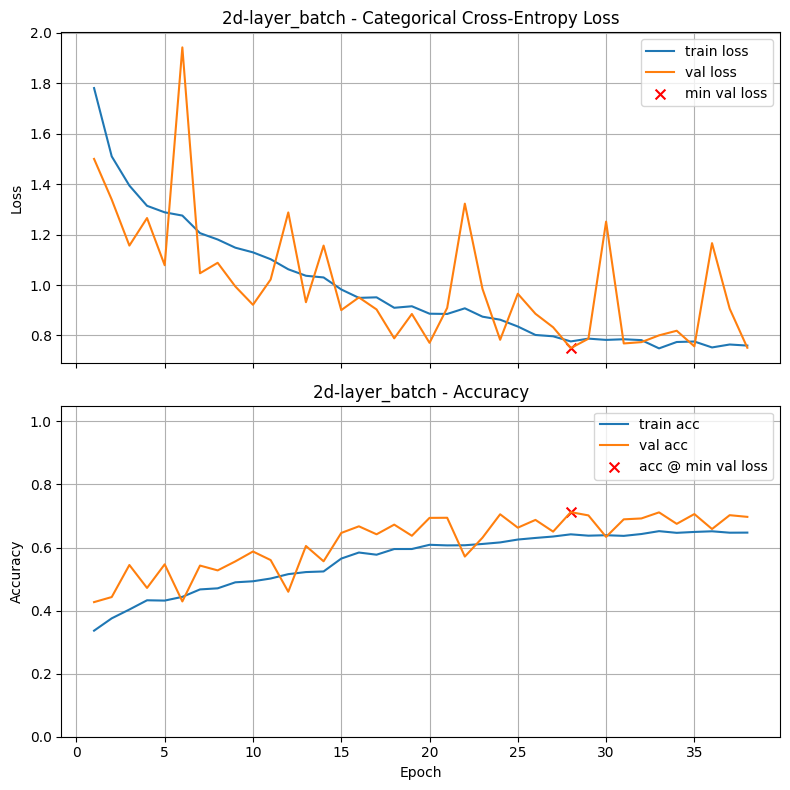

Final Training Loss:            0.7599
Final Training Accuracy:        0.6473
Final Validation Loss:          0.7512
Final Validation Accuracy:      0.6972
Minimum Validation Loss:        0.7499 (Epoch 28)
Validation Accuracy @ Min Loss: 0.7122

Test Loss: 0.7895
Test Accuracy: 0.6953

Validation-Test Gap (accuracy): 0.016864

Execution Time: 00:08:39

dense_batch



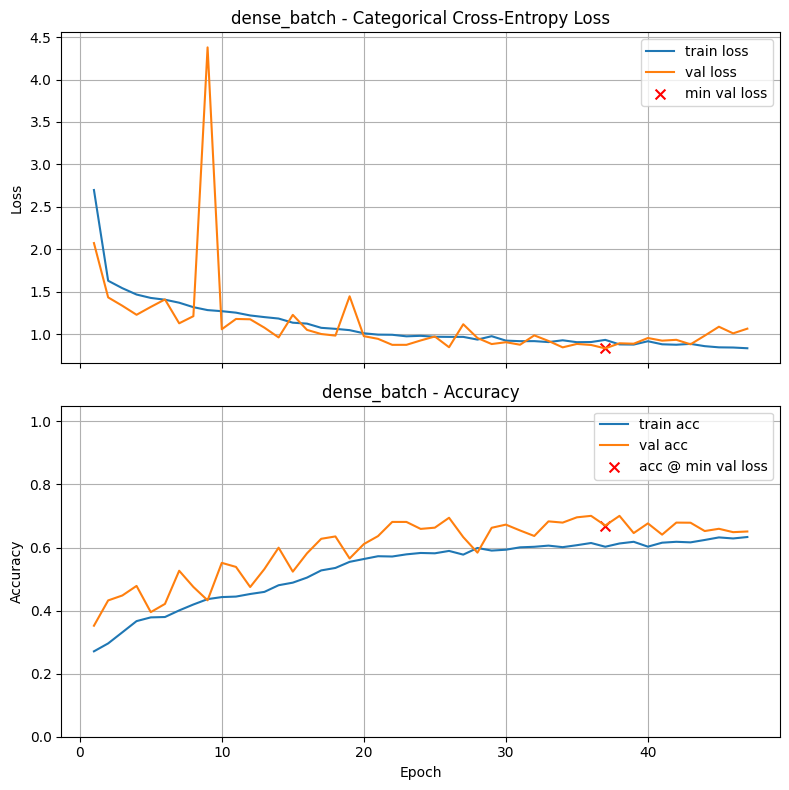

Final Training Loss:            0.8343
Final Training Accuracy:        0.6333
Final Validation Loss:          1.0650
Final Validation Accuracy:      0.6509
Minimum Validation Loss:        0.8327 (Epoch 37)
Validation Accuracy @ Min Loss: 0.6698

Test Loss: 0.8502
Test Accuracy: 0.6837

Validation-Test Gap (accuracy): 0.013909

Execution Time: 00:09:36

drop_out_batch



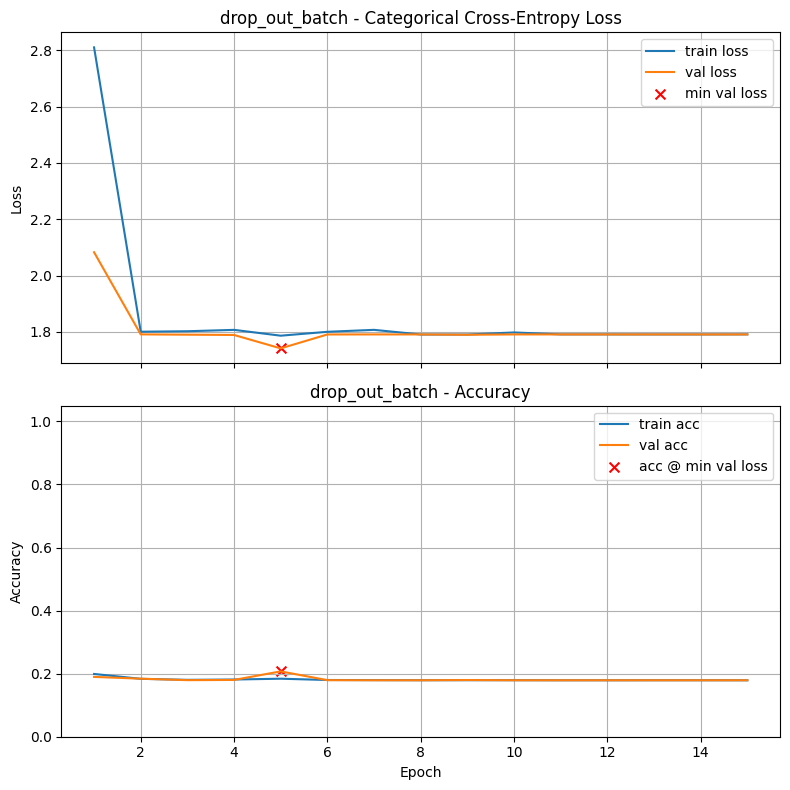

Final Training Loss:            1.7909
Final Training Accuracy:        0.1790
Final Validation Loss:          1.7908
Final Validation Accuracy:      0.1790
Minimum Validation Loss:        1.7412 (Epoch 5)
Validation Accuracy @ Min Loss: 0.2072

Test Loss: 1.7504
Test Accuracy: 0.1977

Validation-Test Gap (accuracy): 0.009537

Execution Time: 00:02:41


In [26]:
# Model with Batch Normalization

model_list2 = []


# model 1 change lr #1
he = initializers.HeNormal()                                # best initializer for relu

model_learnrate2 = models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Flatten(),
  Dense(64, activation="relu",kernel_initializer=he),
  Dropout(0.5),
  Dense(num_classes, activation="softmax")
],name="learn_rate_batch")
hist1_2 = train_and_test(model_learnrate2,lr_schedule=1e-4,title="lr-adjust-batch",return_history=True)
model_list2.append(hist1_2)

# model 2 change width #2
he = initializers.HeNormal()                                # best initializer for relu

model_layer_width2= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(128, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Flatten(),
  Dense(64, activation="relu",kernel_initializer=he),
  Dropout(0.5),
  Dense(num_classes, activation="softmax")
],name="layer_width")
hist2_2 = train_and_test(model_layer_width2,title="layer-width_bacth",return_history=True)
model_list2.append(hist2_2)

# model 3 add 2d layer #3
he = initializers.HeNormal()                                # best initializer for relu

model_conv2d2= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(128, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Flatten(),
  Dense(64, activation="relu",kernel_initializer=he),
  Dropout(0.5),
  Dense(num_classes, activation="softmax")
],name="2d-layer_batch")
hist3_2 = train_and_test(model_conv2d2,title="2d-layer_batch",return_history=True)
model_list2.append(hist3_2)

# model 4 dense #4
he = initializers.HeNormal()                                # best initializer for relu

model_dense2= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Flatten(),
  Dense(128, activation="relu",kernel_initializer=he),
  Dropout(0.5),
  Dense(num_classes, activation="softmax")
],name="dense_batch")
hist4_2 = train_and_test(model_dense2,title="dense_batch",return_history=True)
model_list2.append(hist4_2)


# model 6 change dropout #6
he = initializers.HeNormal()                                # best initializer for relu

model_dropout2= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Flatten(),
  Dense(64, activation="relu",kernel_initializer=he),
  Dropout(0.75),
  Dense(num_classes, activation="softmax")
],name="dropout_batch")
hist6_2 = train_and_test(model_dropout2,title="drop_out_batch",return_history=True)
model_list2.append(hist6_2)

### Graded Questions

In [27]:
# Set a2a to the number of the individual "tweak" which provided the best validation accuracy at the epoch of minimum validation loss

a2a = 1             # Replace with integer 1 - 6; replace with -1 if you found no tweak which improved the results

In [28]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2a = {a2a}')


a2a = 1


In [33]:
# Set a2b to the validation accuracy found by the choice specified in Question a2a (your best model for this problem)

a2b = max(model_list2[0].history['val_accuracy'])              # Replace 0.0 with your answer

In [34]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2b = {a2b:.4f}')

a2b = 0.8088


## Problem Three: Global Average Pooling

As we saw in this week's Coding Video,
**Global Average Pooling** is a simple layer that replaces the `Flatten → Dense` part of a CNN (please review that part of the Coding Notebook, which contains a description of this important technique).

In practice, swapping `Flatten` for `GlobalAveragePooling2D` often improves stability and validation performance — definitely worth considering!


**Task:**
Modify your best model from Problems 1 & 2 to use a `GlobalAveragePooling2D()` layer instead of a flatten-and-dense block.

**Next Steps:**

* Replace the sequence between the last `Conv2D` and output layers, for example:

     
          MaxPooling2D((2, 2)),
          Flatten(),
          Dense(64, activation='relu', kernel_initializer=initializers.HeNormal()),
          Dropout(0.5),   

  with a single `GlobalAveragePooling2D()` layer.
* Train the model and observe how performance and training curves change.
* Try at least one of tweaks from Problem 1 to see if you can improve your results in this new design.
* Compare results and answer the graded questions.

**Optional:**
Experiment with `GlobalMaxPooling2D()` as an alternative and compare its behavior to `GlobalAveragePooling2D()`.




lr-adjust-batch



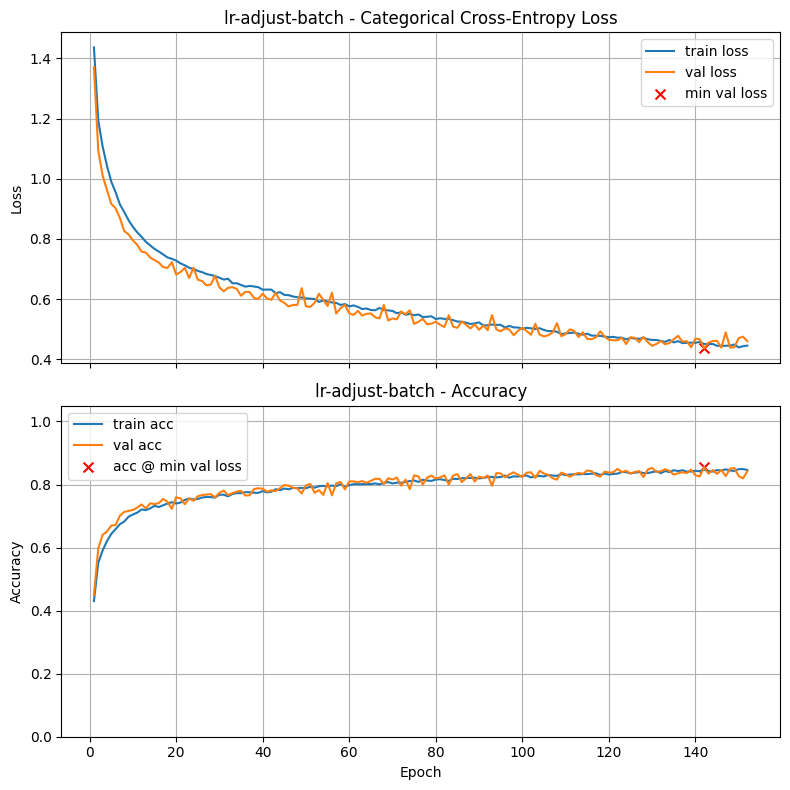

Final Training Loss:            0.4453
Final Training Accuracy:        0.8460
Final Validation Loss:          0.4599
Final Validation Accuracy:      0.8424
Minimum Validation Loss:        0.4364 (Epoch 142)
Validation Accuracy @ Min Loss: 0.8552

Test Loss: 0.4564
Test Accuracy: 0.8480

Validation-Test Gap (accuracy): 0.007207

Execution Time: 00:24:03

layer-width_bacth



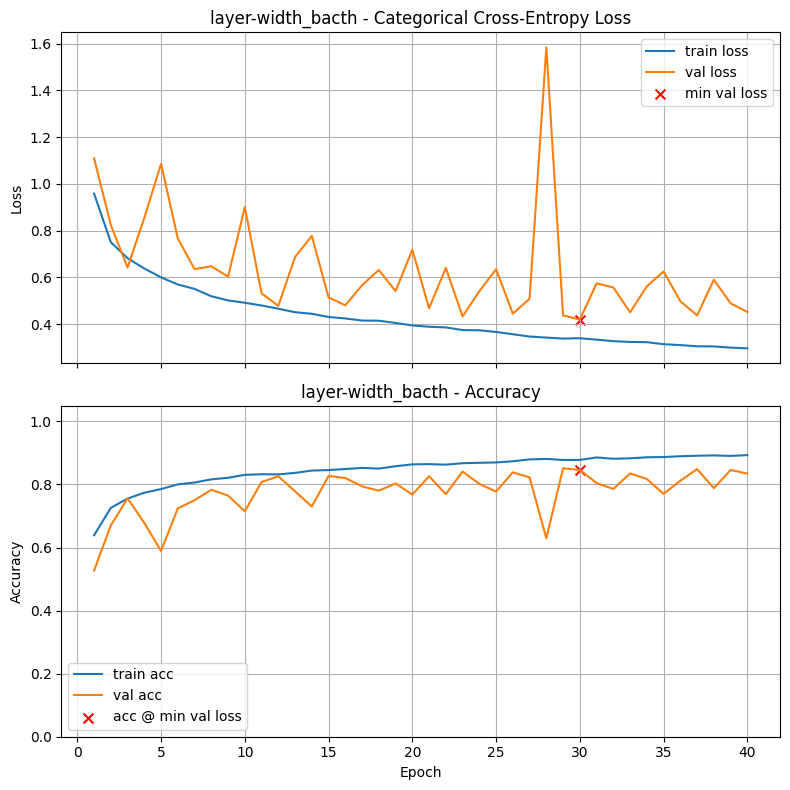

Final Training Loss:            0.2961
Final Training Accuracy:        0.8931
Final Validation Loss:          0.4518
Final Validation Accuracy:      0.8345
Minimum Validation Loss:        0.4191 (Epoch 30)
Validation Accuracy @ Min Loss: 0.8459

Test Loss: 0.4725
Test Accuracy: 0.8420

Validation-Test Gap (accuracy): 0.003934

Execution Time: 00:11:03

2d-layer_batch



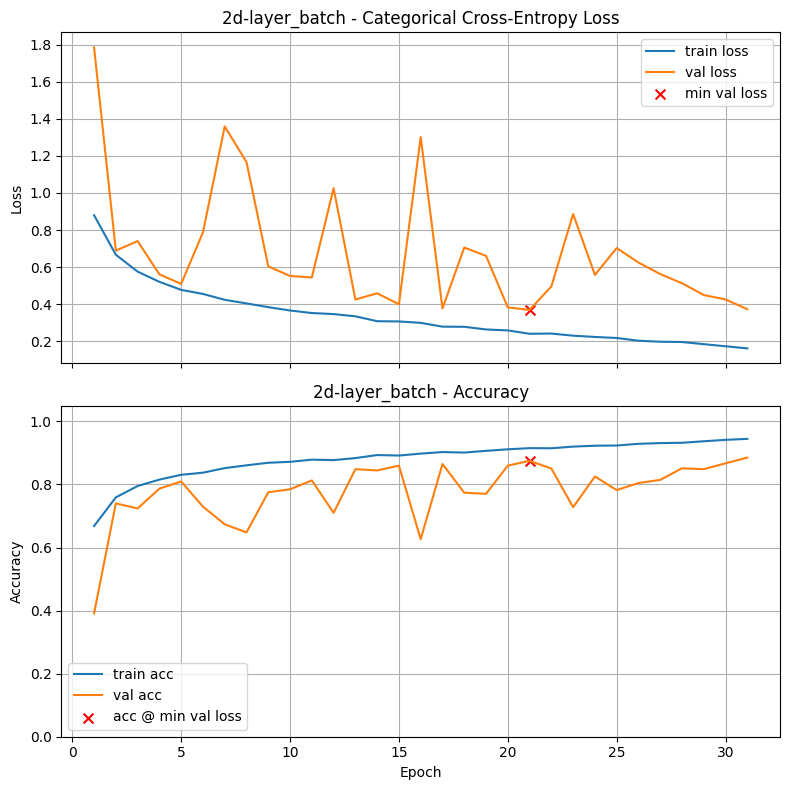

Final Training Loss:            0.1610
Final Training Accuracy:        0.9445
Final Validation Loss:          0.3723
Final Validation Accuracy:      0.8852
Minimum Validation Loss:        0.3687 (Epoch 21)
Validation Accuracy @ Min Loss: 0.8748

Test Loss: 0.3538
Test Accuracy: 0.8783

Validation-Test Gap (accuracy): 0.003512

Execution Time: 00:06:46

dense_batchg



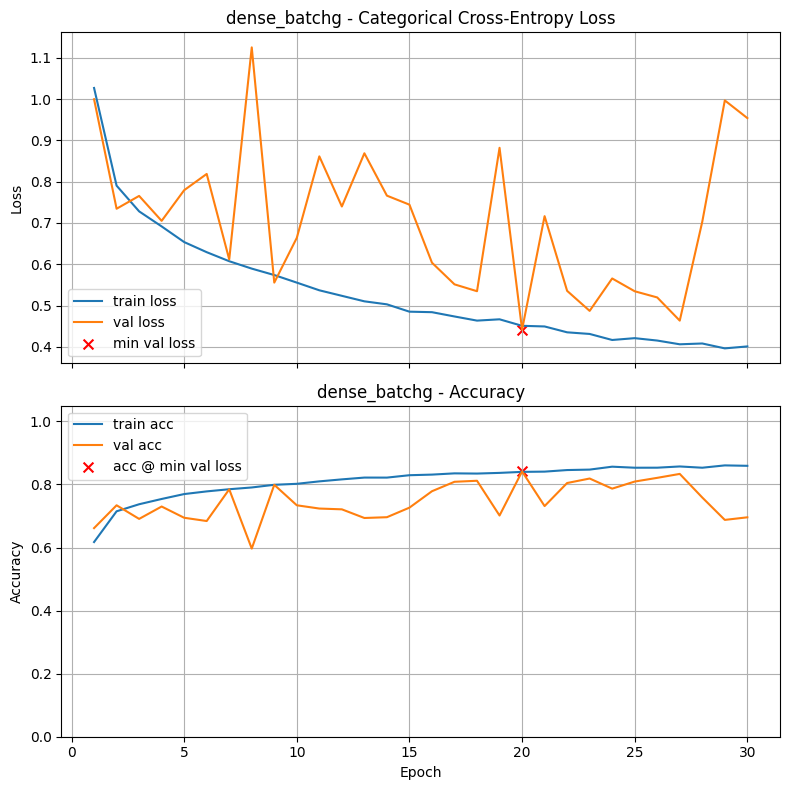

Final Training Loss:            0.4011
Final Training Accuracy:        0.8591
Final Validation Loss:          0.9540
Final Validation Accuracy:      0.6958
Minimum Validation Loss:        0.4415 (Epoch 20)
Validation Accuracy @ Min Loss: 0.8413

Test Loss: 0.4603
Test Accuracy: 0.8400

Validation-Test Gap (accuracy): 0.001298

Execution Time: 00:04:50

drop_out_batch



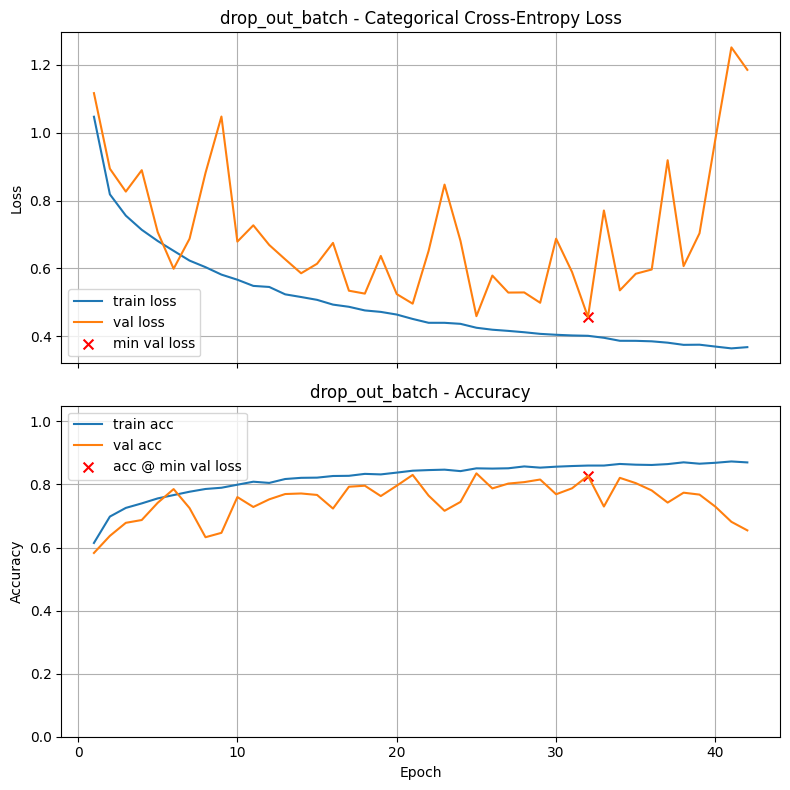

Final Training Loss:            0.3678
Final Training Accuracy:        0.8699
Final Validation Loss:          1.1853
Final Validation Accuracy:      0.6544
Minimum Validation Loss:        0.4566 (Epoch 32)
Validation Accuracy @ Min Loss: 0.8274

Test Loss: 0.4802
Test Accuracy: 0.8293

Validation-Test Gap (accuracy): 0.001944

Execution Time: 00:06:42


In [35]:
# Global pool

# Model with Batch Normalization

model_list2g = []


# model 1 change lr #1
he = initializers.HeNormal()                                # best initializer for relu

model_learnrate2g = models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  GlobalAveragePooling2D(),
  Dense(num_classes, activation="softmax")
],name="learn_rate_batch")
hist1_2g = train_and_test(model_learnrate2g,lr_schedule=1e-4,title="lr-adjust-batch",return_history=True)
model_list2g.append(hist1_2g)

# model 2 change width #2
he = initializers.HeNormal()                                # best initializer for relu

model_layer_width2g= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(128, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  GlobalAveragePooling2D(),
  Dense(num_classes, activation="softmax")
],name="layer_width")
hist2_2g = train_and_test(model_layer_width2g,title="layer-width_bacth",return_history=True)
model_list2g.append(hist2_2g)

# model 3 add 2d layer #3
he = initializers.HeNormal()                                # best initializer for relu

model_conv2d2g= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(128, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  GlobalAveragePooling2D(),
  Dense(num_classes, activation="softmax")
],name="2d-layer_batch")
hist3_2g = train_and_test(model_conv2d2g,title="2d-layer_batch",return_history=True)
model_list2g.append(hist3_2g)

# model 4 dense #4
he = initializers.HeNormal()                                # best initializer for relu

model_dense2g= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  GlobalAveragePooling2D(),
  Dense(num_classes, activation="softmax")
],name="dense_batchg")
hist4_2g = train_and_test(model_dense2g,title="dense_batchg",return_history=True)
model_list2g.append(hist4_2g)


# model 6 change dropout #6
he = initializers.HeNormal()                                # best initializer for relu

model_dropout2g= models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  GlobalAveragePooling2D(),
  Dense(num_classes, activation="softmax")
],name="dropout_batch")
hist6_2g = train_and_test(model_dropout2g,title="drop_out_batch",return_history=True)
model_list2g.append(hist6_2g)


### Graded Questions

In [36]:
# Set a3a to the number of the individual "tweak" which provided the best validation accuracy at the epoch of minimum validation loss

a3a = 3             # Replace with integer 1 - 6; replace with -1 if you found no tweak which improved the results

In [37]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a3a = {a3a}')


a3a = 3


In [44]:
# Set a3b to the validation accuracy found by the choice specified in Question a3a (your best model for this problem)

a3b = max(model_list2g[2].history['val_accuracy'])                # Replace 0.0 with your answer

In [45]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a3b = {a3b:.4f}')

a3b = 0.8852


## Problem Four: ReduceLROnPlateau

`ReduceLROnPlateau` is a widely used learning rate scheduling technique. It monitors a validation metric (usually `val_loss`) and reduces the learning rate when progress stalls, allowing the model to refine training at a smaller step size. This is one of the most useful scheduling tools (along with the essential Early Stopping) to have in your toolbox.

**Task:**
Augment your best model found so far in Problems 1 - 3 with the `ReduceLROnPlateau` callback during training.

**Next Steps:**

* Add the callback parameter to `train_and_test`:

  ```python
  callbacks=[reduce_lr]
  ```

* Start with **`factor=0.5`** (monitor `val_loss`, `patience=2–3`, `cooldown=1`, `min_lr=1e-5` for Adam).
* **Practical playbook:**

  * If plateau persists after one reduction → try **`factor=0.3`**, then **`0.2`**.
  * If a reduction hurts validation noticeably → try **`factor=0.7–0.8`** or increase **`patience`**.
  * Leave **`cooldown=1`** unless you see too-frequent drops.
* Experiment with **`patience` = 3, 5, 8** and **`min_delta` = `1e-4` vs `1e-3`** to gauge sensitivity.
* Choose the configuration with the best validation results—or note that ReduceLROnPlateau didn’t help (rare!).
* Answer the graded questions.




reduce_lr



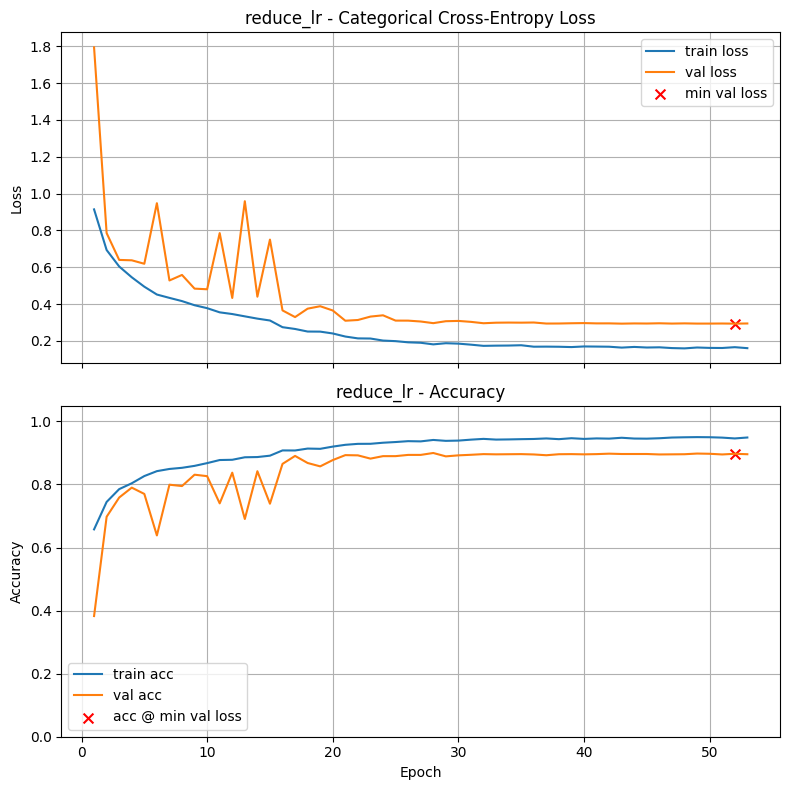

Final Training Loss:            0.1602
Final Training Accuracy:        0.9489
Final Validation Loss:          0.2943
Final Validation Accuracy:      0.8959
Minimum Validation Loss:        0.2933 (Epoch 52)
Validation Accuracy @ Min Loss: 0.8973

Test Loss: 0.2946
Test Accuracy: 0.9000

Validation-Test Gap (accuracy): 0.003424

Execution Time: 00:11:22


In [46]:
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',    # Quantity to be monitored.
    factor=0.5,            # Factor by which the learning rate will be reduced.
                           # new_lr = lr * factor
    patience=3,            # Number of epochs with no improvement
                           # after which learning rate will be reduced.
    min_delta=1e-4,        # Threshold for measuring the new optimum,
                           # to only focus on significant changes.
    cooldown=1,            # Number of epochs to wait before resuming
                           # normal operation after lr has been reduced.
    min_lr=1e-5,           # Lower bound on the learning rate.
    verbose=0,             # 0: quiet, 1: update messages.
)

# Best Model
he = initializers.HeNormal()                                # best initializer for relu
model4 = models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(128, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  GlobalAveragePooling2D(),
  Dense(num_classes, activation="softmax")
],name="dropout_batch")
hist_reduce = train_and_test(model4,callbacks=[reduce_lr],title="reduce_lr",return_history=True)


reduce_lr_lowfactor



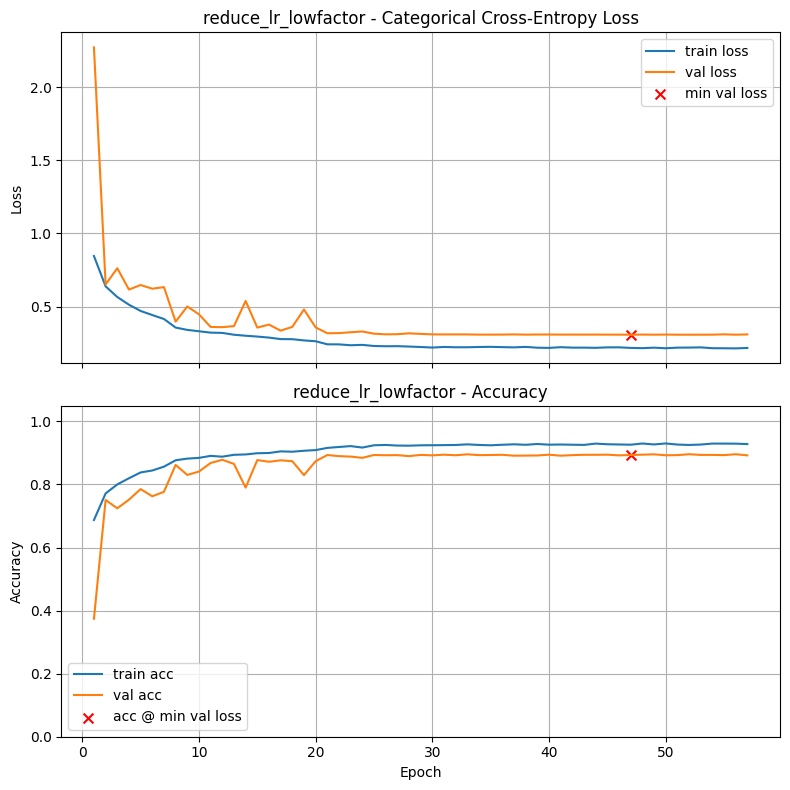

Final Training Loss:            0.2169
Final Training Accuracy:        0.9280
Final Validation Loss:          0.3096
Final Validation Accuracy:      0.8923
Minimum Validation Loss:        0.3075 (Epoch 47)
Validation Accuracy @ Min Loss: 0.8934

Test Loss: 0.3104
Test Accuracy: 0.8950

Validation-Test Gap (accuracy): 0.001633

Execution Time: 00:11:56


In [47]:
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',    # Quantity to be monitored.
    factor=0.3,            # Factor by which the learning rate will be reduced.
                           # new_lr = lr * factor
    patience=3,            # Number of epochs with no improvement
                           # after which learning rate will be reduced.
    min_delta=1e-4,        # Threshold for measuring the new optimum,
                           # to only focus on significant changes.
    cooldown=1,            # Number of epochs to wait before resuming
                           # normal operation after lr has been reduced.
    min_lr=1e-5,           # Lower bound on the learning rate.
    verbose=0,             # 0: quiet, 1: update messages.
)

# Best Model
he = initializers.HeNormal()                                # best initializer for relu
model4_2 = models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(128, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  GlobalAveragePooling2D(),
  Dense(num_classes, activation="softmax")
],name="reduce_lr_lowfactor")
hist_reduce = train_and_test(model4_2,callbacks=[reduce_lr],title="reduce_lr_lowfactor",return_history=True)


reduce_lr_highfactor



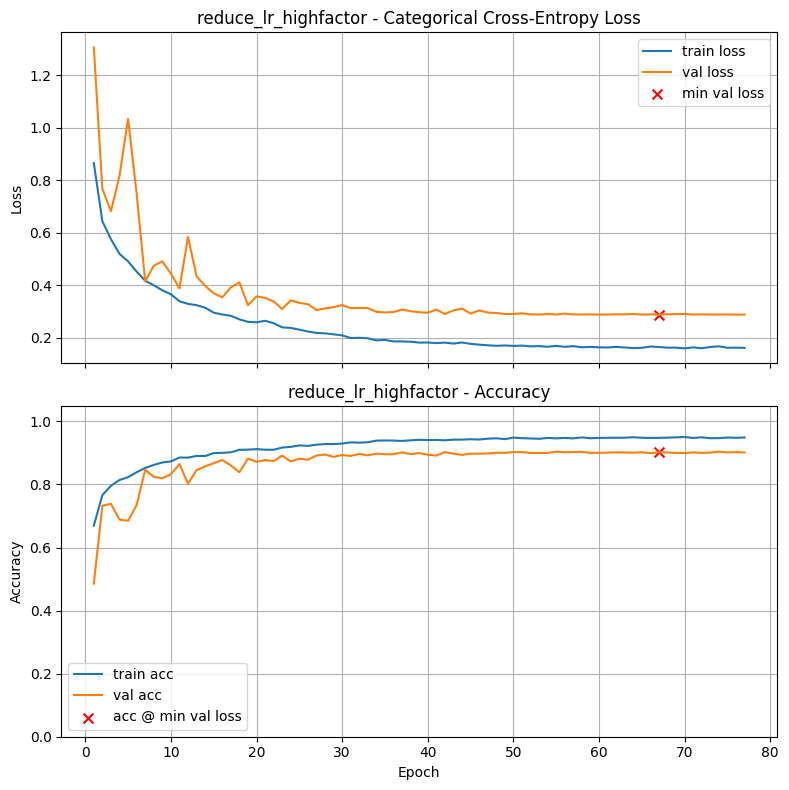

Final Training Loss:            0.1618
Final Training Accuracy:        0.9489
Final Validation Loss:          0.2887
Final Validation Accuracy:      0.9012
Minimum Validation Loss:        0.2882 (Epoch 67)
Validation Accuracy @ Min Loss: 0.9019

Test Loss: 0.2924
Test Accuracy: 0.8977

Validation-Test Gap (accuracy): 0.004259

Execution Time: 00:16:56


In [48]:
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',    # Quantity to be monitored.
    factor=0.7,            # Factor by which the learning rate will be reduced.
                           # new_lr = lr * factor
    patience=3,            # Number of epochs with no improvement
                           # after which learning rate will be reduced.
    min_delta=1e-4,        # Threshold for measuring the new optimum,
                           # to only focus on significant changes.
    cooldown=1,            # Number of epochs to wait before resuming
                           # normal operation after lr has been reduced.
    min_lr=1e-5,           # Lower bound on the learning rate.
    verbose=0,             # 0: quiet, 1: update messages.
)

# Best Model
he = initializers.HeNormal()                                # best initializer for relu
model4_3 = models.Sequential([
  Input(shape=INPUT_SHAPE),

  Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(64, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  MaxPooling2D(2),

  Conv2D(128, (3,3), activation="relu", kernel_initializer=he, padding="same"),
  BatchNormalization(),
  GlobalAveragePooling2D(),
  Dense(num_classes, activation="softmax")
],name="reduce_lr_highfactor")
hist_reduce = train_and_test(model4_3,callbacks=[reduce_lr],title="reduce_lr_highfactor",return_history=True)

### Graded Questions

In [51]:
# Set a4a to the factor parameter which gave the best validation accuracy at the point of minimum validation loss

a4a = 0.7             # Replace with your best factor value, or set to -1 if reduce on plateau did not help at all

In [52]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a4a = {a4a:.2f}')

a4a = 0.70


In [53]:
# Set a4b to the validation accuracy found by the choice specified in Question a4a (your best model for this problem)

a4b = max(hist_reduce.history['val_accuracy'])             # Replace 0.0 with your answer

In [54]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a4b = {a4b:.4f}')

a4b = 0.9041


## Problem Five: A Very Deep CNN (VGG-16 Style)

 We will now experiment with the VGG-16 design introduced in the Coding Notebook and Video and see how it does on this dataset. For a beautiful description of the model and its significance, see [Explanation of VGG-16](https://viso.ai/deep-learning/vgg-very-deep-convolutional-networks/) :
        

![Screenshot 2025-09-19 at 6.50.24 AM.png](attachment:62fa0824-bb06-4663-a6a5-da8cca8f4ab3.png)


In this exercise you’ll **only vary the learning rate**. Don’t change any other hyperparameters. Your goal is to observe how LR affects convergence speed, stability, and final validation performance compared to your smaller baselines. This sets up next week’s **transfer learning** with pretrained models.

#### Starting point

* Optimizer: **Adam**
* **Recommended LR to start:** `1e-3`(Adam default)

#### What LR values to try (coarse → fine)

Try a short sweep like:

```
[1e-2, 3e-3, 1e-3, 3e-4, 1e-4, 3e-5, 1e-5]
```

Then, as time allows,  zoom in around the best.

#### How to judge “best”

* Primary: **best validation accuracy at epoch of lowest validation loss**
* Secondary: **time-to-best** (fewer epochs to reach a strong val metric) and **curve shape** (smooth vs. noisy/oscillatory).

#### What symptoms mean

* **LR too high:** training loss spikes or oscillates; val metrics erratic, occasional NaNs/divergence.
* **LR too low:** very slow improvement; long flat regions; never reaches your smaller models’ performance.


**Tip:** Keep LR **constant** during each run (don’t schedule) so you isolate its effect.




VGG-style Large



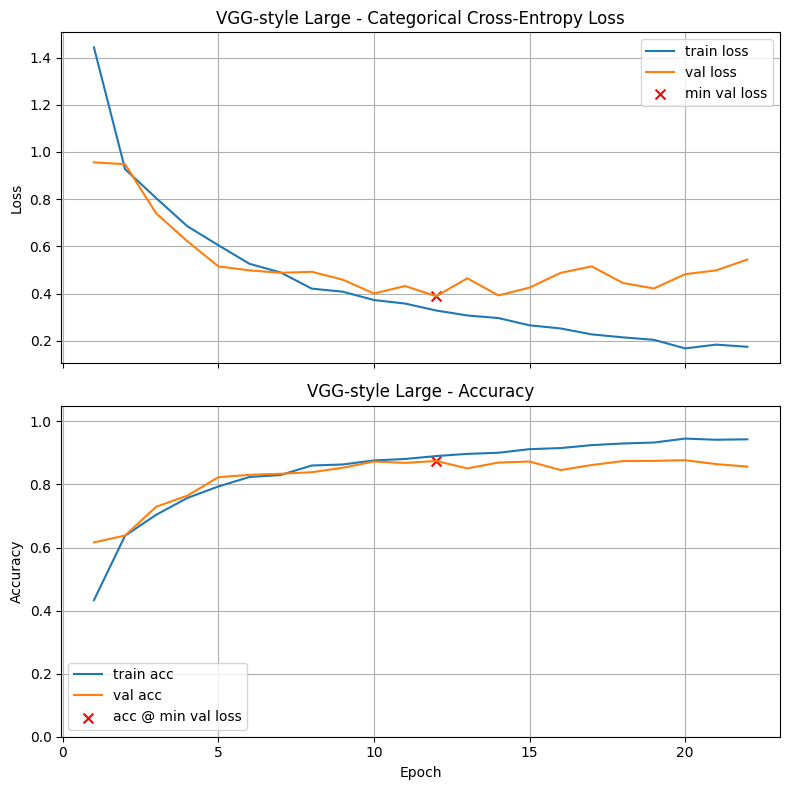

Final Training Loss:            0.1744
Final Training Accuracy:        0.9432
Final Validation Loss:          0.5441
Final Validation Accuracy:      0.8566
Minimum Validation Loss:        0.3888 (Epoch 12)
Validation Accuracy @ Min Loss: 0.8745

Test Loss: 0.3958
Test Accuracy: 0.8703

Validation-Test Gap (accuracy): 0.004132

Execution Time: 00:35:20


In [58]:
he = initializers.HeNormal()
l2rate = 1e-4
l2reg = regularizers.l2(l2rate)   # set to None to disable or tweak the value

model_vgg_16 = models.Sequential([
    layers.Input(shape=(150, 150, 3)),

    # Block 1
    layers.Conv2D(64, (3,3), padding='same', activation='relu', kernel_initializer=he),
    layers.Conv2D(64, (3,3), padding='same', activation='relu', kernel_initializer=he),
    layers.MaxPooling2D(),

    # Block 2
    layers.Conv2D(128, (3,3), padding='same', activation='relu', kernel_initializer=he),
    layers.Conv2D(128, (3,3), padding='same', activation='relu', kernel_initializer=he),
    layers.MaxPooling2D(),

    # Block 3
    layers.Conv2D(256, (3,3), padding='same', activation='relu', kernel_initializer=he),
    layers.Conv2D(256, (3,3), padding='same', activation='relu', kernel_initializer=he),
    layers.Conv2D(256, (3,3), padding='same', activation='relu', kernel_initializer=he),
    layers.MaxPooling2D(),

    # Block 4 (NO MaxPool here -> leaves 3×3×512)
    layers.Conv2D(512, (3,3), padding='same', activation='relu', kernel_initializer=he),
    layers.Conv2D(512, (3,3), padding='same', activation='relu', kernel_initializer=he),
    layers.Conv2D(512, (3,3), padding='same', activation='relu', kernel_initializer=he),

    # Global pooling meaningfully summarizes the 3×3 map
    layers.GlobalAveragePooling2D(),   # swap to GlobalMaxPooling2D() to compare

    # Compact head
    layers.Dense(256, activation='relu', kernel_initializer=he,
                 kernel_regularizer=l2reg),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Uncomment the next line to run

deep_hist = train_and_test(model_vgg_16,lr_schedule=1e-3,title="VGG-style Large")


### Graded Questions

In [56]:
# Set a5a to the learning rate which gave the best validation accuracy at the point of minimum validation loss

a5a = 1e-4             # Replace with your best learning rate

In [57]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a5a = {a5a:.8f}')

a5a = 0.00010000


In [61]:
# Set a5b to the validation accuracy found by the choice specified in Question a5a (your best model for this problem)

a5b = 0.8703              # Replace 0.0 with your answer

In [62]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a5b = {a5b:.4f}')

a5b = 0.8703


## All Results

This will print out the results from all experiments, with titles as keys. I use this all the time to keep track of experiments!

In [ ]:
print_results()